In [3]:
import sys
# sys.path.append('/Users/austindestcroix/root_Mar2022/installdir1/lib/')

import ROOT
from ROOT import TFile, TCanvas, TTree
from ROOT import gROOT, gBenchmark, gDirectory, gPad, gStyle
from ROOT import TH1F, THStack, TH1, TGraphErrors, TH3F
from ROOT import TF1, TSpectrum, TFitResultPtr, TFitResult

Welcome to JupyROOT 6.26/00


In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
## My Functions ##
def openMyROOT(sfile: str, tname = "simOutput"):
    if (ROOT.gSystem.AccessPathName(sfile)) :
        ROOT.Info("openMyROOT", sfile+" does not exist")
        exit(0)
    else:
        f = TFile(sfile)
        return f, f.Get(tname) 
    
## fit info ##
class fitGuesses:
    def __init__(self):
        self.fitRange = 100
        self.mean1 = 0.
        self.mean2 = 0
        self.sig1 = 0
        self.sig2 = 0
        return
    

class runInfo:
    def __init__(self, s):
        self.name = s
        self.h = float((s.split("-")[0]).removeprefix("h_"))
        self.rho = float((s.split("-")[1]).removeprefix("density_"))
        self.ly = float((s.split("-")[2]).removeprefix("LY_").removesuffix(".root"))
        
        self.fg = fitGuesses()
        return
    
    def print(self):
        print("fileName:", self.name)
        print("h = %f cm \nrho = %f g/cm3 \nly = %i ph/MeV \n"%(self.h, self.rho, self.ly))
        return
    
    def addFile(self, batchPath, s, tname = "simOutput"):
        f, t = openMyROOT(batchPath + s, tname)
        self.file = f
        self.tt = t
        return
    
    def addHist(self, h : TH1, name):
        setattr(self, name, h)

In [6]:
## formatting ##
myColList = [1, 2, 3, 4, 6, 7, 8, 9, 30, 40, 46, 49]

In [7]:
# load file list (from wherever we are analyzing data)
# sBatch = "../Batch/alphas_v1-5k/"
# sFList = "fileList-2022-06-06.txt"
sBatch = "../Batch/alphas_v1/"
sFList = "fileList-2022-06-07.txt"
fList = np.loadtxt(sBatch+sFList, dtype = str)

In [8]:
## Building run objects, adding files and trees to run objects##
if "runObjs" in vars():
    del runObjs
runObjs = []
for f in fList:
    ri = runInfo(f)
    ri.addFile(sBatch, f)
    runObjs.append(ri)
    # ri.print()

In [9]:
## adding histograms to run objects ##
nbin = 200
peMax = 2000

sVar = "fNPE"
for i, ro in enumerate(runObjs):
    hName = "h_%s_%s" % (sVar, ro.name)
    h = TH1F(hName, hName, nbin, 0, peMax)
    ro.addHist(h, "h"+sVar[1:])
    
    a = "%s>>%s" % (sVar, hName)
    ro.tt.Draw(a, "", "goff")
    ro.hNPE.SetLineColor(myColList[i])

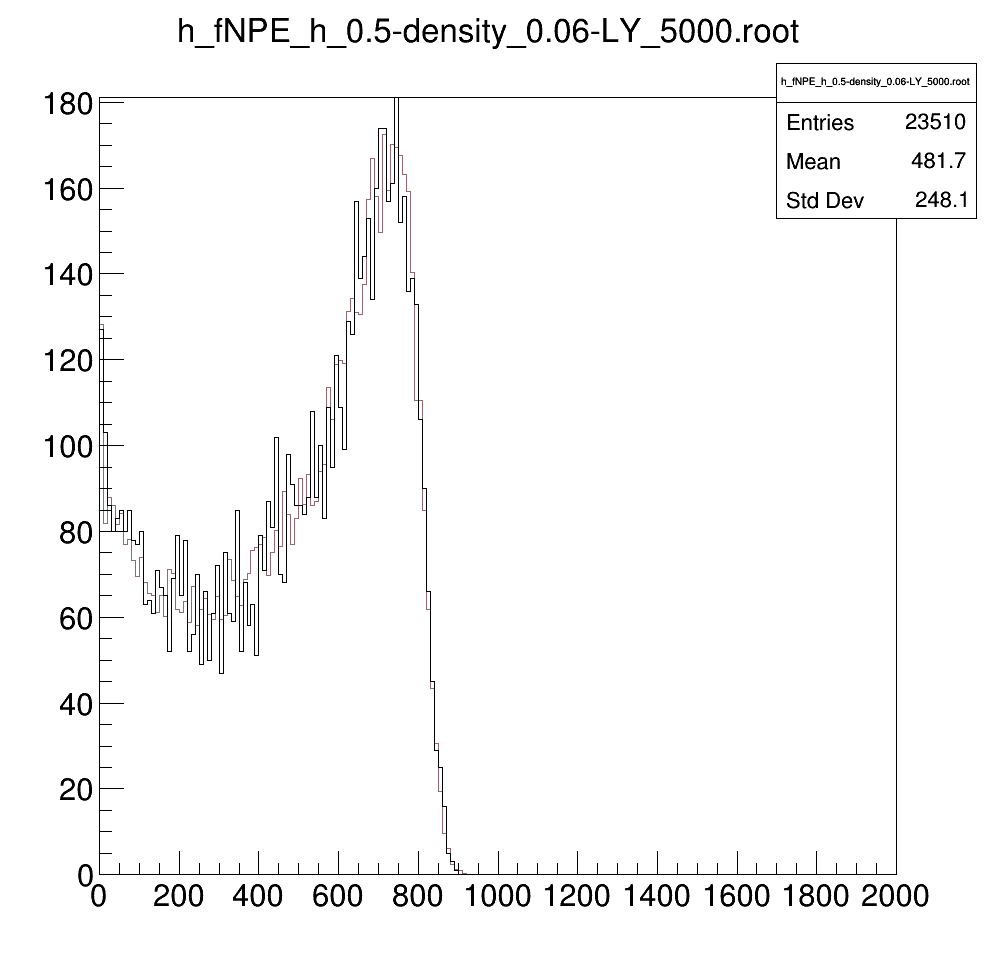

In [10]:
### comparing new 'noQuenching' simulations ###
s_noq_low = "h_0.5-density_0.002-LY_5000.root"
s_noq_high = "h_0.5-density_0.06-LY_5000.root"
sBatch_noq = sBatch[:-1]+"_noQuenching/"
ri_lowRho = runInfo(s_noq_low)
ri_lowRho.addFile(sBatch_noq, ri_lowRho.name)

ri_hiRho = runInfo(s_noq_high)
ri_hiRho.addFile(sBatch_noq, ri_hiRho.name)

cnoq = TCanvas("cnoq", "cnoq", 1000, 1000)

runObjs[-1].hNPE.Scale(ri_hiRho.tt.GetEntries()/runObjs[-1].tt.GetEntries())
runObjs[-1].hNPE.Draw("hist")
ri_hiRho.tt.Draw("fNPE", "", "hist same")

cnoq.Draw()


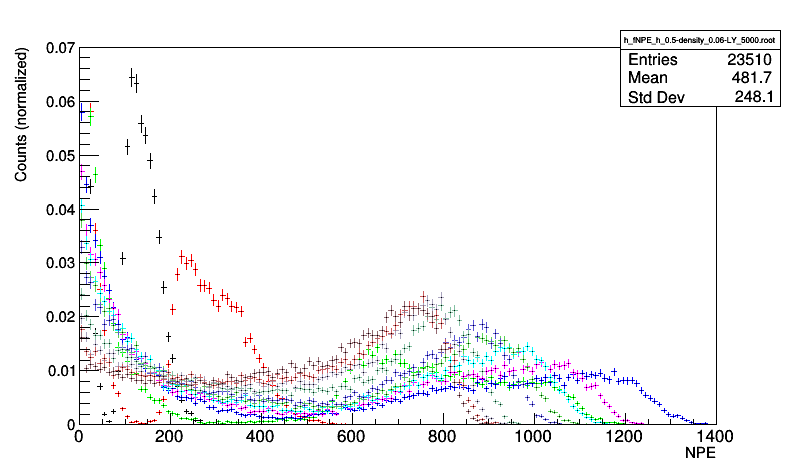

In [11]:
if "hs" in locals():
    del hs

# fdubGaus = 
## manipulating histograms ##
for r in runObjs:
    h = r.hNPE
    h.Scale(1/h.Integral())
    h.GetXaxis().SetRangeUser(0, 1500)
    h.GetYaxis().SetRangeUser(0., 0.15)
    
    # h.SetMarkerStyle(34)
    # h.SetMarkerSize(1)
    # h.SetMaximum(0.4)
    ### fitting ###
    # nLast = h.FindLastBinAbove(0.002)
    # xLast = h.GetXaxis().GetBinCenter(nLast)
    # fit = (h.Fit("gaus", "QS", "", xLast-200, xLast)).Get()

c1 = TCanvas( 'c1', 'The THStack canvas', 800, 500)

hs = THStack("hs", "");
hs.SetMaximum(0.07)
for r in runObjs:
    hs.Add(r.hNPE)
    # r.hNPE.GetEntries()

# hs.SetMaximum(2000)
#hs.SetMinimum(10)
hs.Draw("nostack")
hs.GetXaxis().SetLimits(0, 1400)
hs.GetXaxis().SetTitle("NPE")
hs.GetXaxis().SetLabelSize(.04)
hs.GetYaxis().SetTitle("Counts (normalized)")

# c1.cd(0).SetLogy()
c1.Update()
c1.Draw()

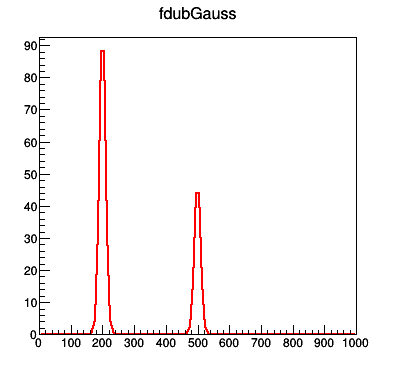

In [12]:
ct = TCanvas("ct", "ct", 400, 400)

fdubGauss = TF1("fdubGauss", "gaus(0) + gaus(3)")
# fdubGauss.SetParNames("c1, mean1, sig1")

ff2 = TF1("ff2", "fdubGauss", 0, 1000)
ff2.SetParameters(100, 200, 10, 50, 500, 10)
ff2.Draw("l")

ct.Draw()

mean = 132.676664    sig = 40.144827 
chi2/ndf = 9.799533
mean = 300.317971    sig = 78.751104 
chi2/ndf = 1.120804
mean = 997.707451    sig = 81.916532 
chi2/ndf = 0.629694
mean = 1163.455099    sig = 81.762295 
chi2/ndf = 0.919921
mean = 1054.853972    sig = 71.380991 
chi2/ndf = 1.087132
mean = 976.001491    sig = 65.358936 
chi2/ndf = 0.322165
mean = 923.961825    sig = 62.139861 
chi2/ndf = 1.409066
mean = 879.142811    sig = 67.424404 
chi2/ndf = 1.464773
mean = 802.919100    sig = 64.998732 
chi2/ndf = 1.552413
mean = 771.283770    sig = 58.748758 
chi2/ndf = 1.906689
mean = 748.174844    sig = 61.767987 
chi2/ndf = 2.317926
mean = 742.799250    sig = 55.691860 
chi2/ndf = 1.862933


Info in <TCanvas::Print>: png file spectras1.png has been created


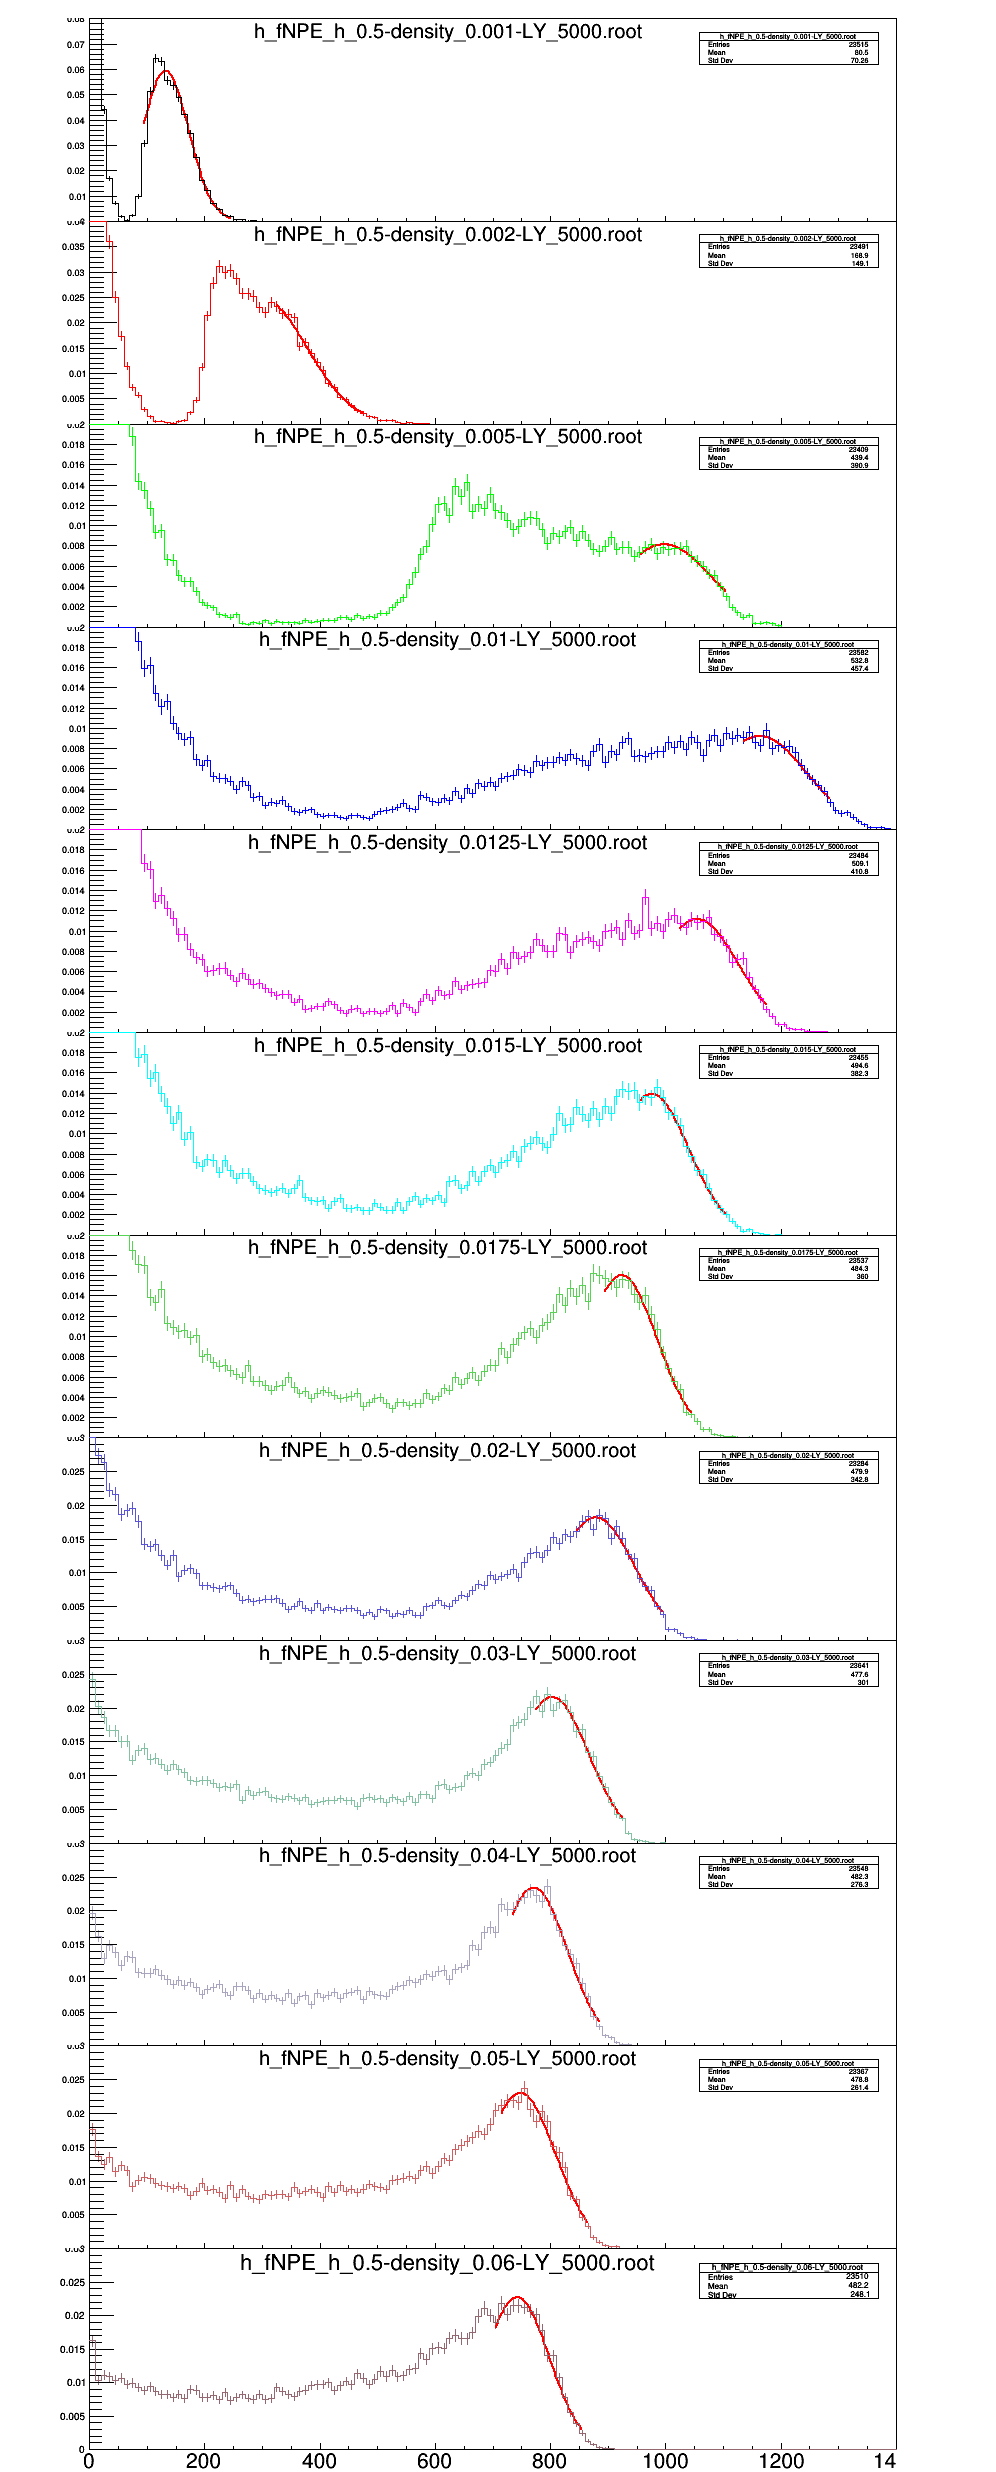

In [13]:
## for plotting ##
xRho = []
xeRho = []
yNPE = []
yeNPE = []

c2 = TCanvas("c2", "c2", 1000, 2500)

c2.Divide(1, len(runObjs), 0.01, 0.0)
yScale = [0.08, 0.04, 0.02, 0.02, 0.02, 0.02, 0.02, 0.03, 0.03, 0.03, 0.03, 0.03]

for i, r in enumerate(runObjs):
    c2.cd(i+1)
    
    r.hNPE.GetXaxis().SetLabelSize(0.1)
    r.hNPE.GetYaxis().SetLabelSize(0.05)
    # gPad.SetTickx(10)
    # gStyle.SetOptStat(0)
    # gStyle.SetOptFit(1111)
    
    ### fitting ###
    nLast = r.hNPE.FindLastBinAbove(0.002)
    xLast = r.hNPE.GetXaxis().GetBinCenter(nLast)
    gap = 150
    # if r.rho < 0.002:
    #     gap = 150
    
    fit = (r.hNPE.Fit("gaus", "SQ", "", xLast-gap, xLast)).Get()
    print("mean = %f    sig = %f \nchi2/ndf = %f" % (fit.Parameter(1), fit.Parameter(2), fit.Chi2()/fit.Ndf()))
    
    # ff2 = TF1("ff2%i"%i, "gaus(0) + gaus(3)", 0, 1000)
    # scaleA = 0.8
    # shift = 200
    # ff2.SetParameters(fit.Parameter(0)*scaleA, fit.Parameter(1), fit.Parameter(2), fit.Parameter(0)*scaleA, fit.Parameter(1)-shift, fit.Parameter(2))
    # ff2.SetLineColor(myColList[i])
    # ff2.Draw("same")
    
    # fit2 = (r.hNPE.Fit("fdubGauss", "QS", "draw", xLast-200, xLast)).Get()
    # fit.Print()
    
    ## for plotting ##
    xRho.append(r.rho)
    xeRho.append(fit.Chi2()/fit.Ndf())
    yNPE.append(fit.Parameter(1))
    yeNPE.append(fit.Parameter(2))
    
    r.hNPE.GetYaxis().SetRangeUser(0., yScale[i])
    r.hNPE.GetXaxis().SetRangeUser(0, 1400)
    r.hNPE.Draw("hist same")
    gStyle.SetTitleSize(0.1, "t")
    gPad.Update()

c2.Update()
c2.Draw()
c2.SaveAs("spectras1.png")

scaled LY = 3571


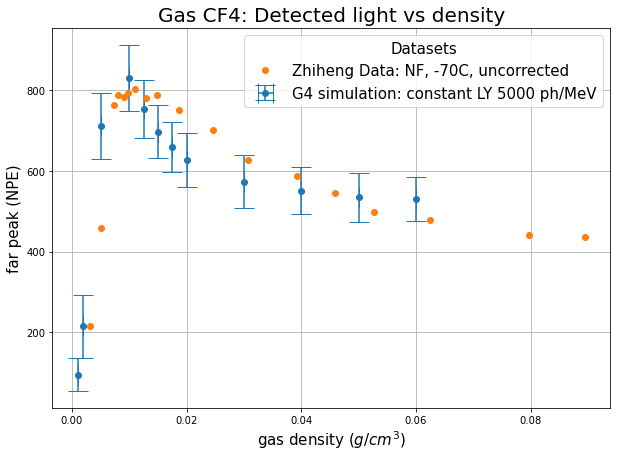

In [14]:


fig, ax = plt.subplots(1, 1, figsize = (10, 7))

lyScale = 1.4
print("scaled LY = %i" % (5000/1.4))
ax.errorbar(xRho, np.array(yNPE)/1.4, yerr = yeNPE, xerr = [0]*len(xRho), linestyle = "", marker = "o", capsize = 10,
           label = "G4 simulation: constant LY 5000 ph/MeV")

ax.set_title("Gas CF4: Detected light vs density", size = 20)
ax.set_xlabel(r"gas density $(g/cm^3)$", size = 15)
ax.set_ylabel("far peak (NPE)", size = 15)

pressure = [200,183,150,130,115,100,80,65,50,40,35,30,27,25,22,20,14,9]
density = [0.089478 , 0.079736 , 0.062423 , 0.05276  , 0.045853 , 0.039206 , 0.030703 , 0.024569 , 0.018625 , 0.01476  , 0.012855 , 0.010968 , 0.0098447, 0.009099 , 0.0079856, 0.0072467, 0.0050458, 0.0032296]
alpha_peaks = [436.5, 441.5, 478.5, 498.5, 545.5, 587.5, 627.5, 702.5, 751.5, 787.5, 780.5, 802.5, 794.5, 783.5, 789.5, 762.5, 459.5, 215.5]

ax.plot(density, alpha_peaks, marker = "o", linestyle = "", label = "Zhiheng Data: NF, -70C, uncorrected")

ax.legend(title = "Datasets", title_fontsize = 15, fontsize = 15)
ax.grid()
plt.savefig("ulj.png", bbox_inches = "tight")
plt.show()


In [16]:
# plt.plot((np.array(xRho) + np.array(density))/2, np.array(yNPE)/1.4 - alpha_peaks)

ValueError: operands could not be broadcast together with shapes (12,) (18,) 